# PAD000016 showcase

This notebook runs `olinkanalyze` on [PRIDE PAD000016](https://www.ebi.ac.uk/pride/archive/projects/PAD000016),
an Olink Explore HT NPX study of cyproterone acetate (CPA) or spironolactone (SPIRO)
gender-affirming hormone therapy and pregnancy.

The SDRF (`GAHT_pregnancy_metadata_SDRF.tsv`) is the study manifest: each row is
a sample, `comment[data file]` names the NPX parquet, and `assay name` is the
plate/run. NPX files are downloaded and loaded from that list. Data lives in
`data/PAD000016/` (gitignored). Install the package first (`pip install -e .`),
then run the cells in order.


## Setup


In [55]:
%matplotlib inline

from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd

import olinkanalyze as oa

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)

print("olinkanalyze", oa.__version__)


olinkanalyze 0.1.0


## SDRF manifest

PAD000016 is hosted on EBI FTP. Download the SDRF first and treat it as the
manifest: `source name` is SampleID, `comment[data file]` is the NPX file to
load, `assay name` is the run, and `factor value[phenotype]` is the analysis
grouping. NPX files listed there are fetched next. EBI FTP can take 30–40
seconds to start transferring.


In [56]:
PRIDE_FTP = "https://ftp.pride.ebi.ac.uk/pride/data/archive/2025/09/PAD000016"
SDRF_NAME = "GAHT_pregnancy_metadata_SDRF.tsv"
SDRF_COLUMNS = {
    "source name": "SampleID",
    "characteristics[organism]": "Organism",
    "characteristics[phenotype]": "CharacteristicsPhenotype",
    "assay name": "Run",
    "comment[label]": "Label",
    "comment[data file]": "DataFile",
    "factor value[phenotype]": "Phenotype",
}


def repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "olinkanalyze").is_dir():
            return candidate
    return here


def fetch(name: str) -> Path:
    dest = DATA / name
    if dest.exists() and dest.stat().st_size > 0:
        print("have", dest.name, dest.stat().st_size, "bytes")
        return dest
    print("downloading", name, "...")
    urlretrieve(f"{PRIDE_FTP}/{name}", dest)
    print("saved", dest)
    return dest


DATA = repo_root() / "data" / "PAD000016"
DATA.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(fetch(SDRF_NAME), sep="\t").rename(columns=SDRF_COLUMNS)
plates = (
    manifest.groupby(["Run", "DataFile"], dropna=False, as_index=False)
    .agg(n_samples=("SampleID", "nunique"))
)
print("plates in SDRF manifest:")
print(plates.to_string(index=False))

for name in plates["DataFile"].dropna().unique():
    fetch(name)

manifest.head()


have GAHT_pregnancy_metadata_SDRF.tsv 11768 bytes
plates in SDRF manifest:
  Run                            DataFile  n_samples
run 1 X201SC23110522-Z01-F004_NPX.parquet         61
run 2     X201SC25020748-Z01-F001.parquet         42
have X201SC23110522-Z01-F004_NPX.parquet 7803173 bytes
have X201SC25020748-Z01-F001.parquet 5924157 bytes


,SampleID,Organism,CharacteristicsPhenotype,Run,Label,DataFile,Phenotype
0,NB177_T3,homo sapiens,pregnancy_trimester_3,run 1,label free,X201SC23110522-Z01-F004_NPX.parquet,pregnancy_trimester_3
1,AA17_0m,homo sapiens,CPA_GAHT_baseline,run 1,label free,X201SC23110522-Z01-F004_NPX.parquet,CPA_GAHT_baseline
2,AA32_6m,homo sapiens,CPA_GAHT_6_months,run 1,label free,X201SC23110522-Z01-F004_NPX.parquet,CPA_GAHT_6_months
3,AA38_6m,homo sapiens,CPA_GAHT_6_months,run 1,label free,X201SC23110522-Z01-F004_NPX.parquet,CPA_GAHT_6_months
4,NB207_T3,homo sapiens,pregnancy_trimester_3,run 1,label free,X201SC23110522-Z01-F004_NPX.parquet,pregnancy_trimester_3


## `read_npx`

Load every NPX file named in the SDRF `DataFile` column. `read_npx` accepts
parquet, runs `check_npx`, and stores the log on `DataFrame.attrs`. These
Explore HT files also contain `PCNormalizedNPX`; `preferred_names` keeps `NPX`
as the quantification column.


In [57]:
PREFERRED = {"quant": "NPX"}

npx_by_run = {}
for row in plates.itertuples(index=False):
    npx_by_run[row.Run] = oa.read_npx(DATA / row.DataFile, preferred_names=PREFERRED)

run1_raw = npx_by_run["run 1"]
run2_raw = npx_by_run["run 2"]

summary = pd.DataFrame(
    {
        run: [
            df["SampleID"].nunique(),
            df["OlinkID"].nunique(),
            df["Panel"].nunique(),
            df.shape[0],
        ]
        for run, df in npx_by_run.items()
    },
    index=["samples", "assays", "panels", "rows"],
)
summary


/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/io/read_npx.py:45: UserWarning: 6 assay(s) exhibited assay QC warnings in column AssayQC: ['OID45034', 'OID45249', 'OID45347', 'OID45353', 'OID45438', 'OID45439']. Consider running clean_npx().
  check_log = check_npx(df, preferred_names=preferred_names)
/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/io/read_npx.py:45: UserWarning: 1 assay(s) exhibited assay QC warnings in column AssayQC: ['OID45439']. Consider running clean_npx().
  check_log = check_npx(df, preferred_names=preferred_names)


,run 1,run 2
samples,71,52
assays,5444,5444
panels,1,1
rows,386524,283088


In [58]:
run1_raw.head()


,SampleID,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,...,NPX,Normalization,PCNormalizedNPX,AssayQC,SampleQC,ExploreVersion
0,NB177_T3,SAMPLE,A1,plate1,D10001,OID45511,...,0.0,Plate control,0.0,NA,PASS,6.7.2
1,AA17_0m,SAMPLE,A2,plate1,D10001,OID45511,...,0.0,Plate control,0.0,NA,PASS,6.7.2
2,AA32_6m,SAMPLE,A3,plate1,D10001,OID45511,...,0.0,Plate control,0.0,NA,PASS,6.7.2
3,AA38_6m,SAMPLE,A4,plate1,D10001,OID45511,...,0.0,Plate control,0.0,NA,PASS,6.7.2
4,NB207_T3,SAMPLE,A5,plate1,D10001,OID45511,...,0.0,Plate control,0.0,NA,PASS,6.7.2


## Join the SDRF onto NPX

Match each NPX `SampleID` to the manifest `source name`. Study samples pick up
phenotype, run, and source file. Control wells (`SC*`, `IPC*`, `NC*`) are not
in the SDRF and stay unlabeled. Assigning columns in place keeps the `check_npx`
log attached.


In [59]:
print(manifest["Phenotype"].value_counts().to_string())
print()
print(manifest.groupby(["Run", "DataFile"]).size().rename("n_samples").to_string())


def add_sample_annotation(df: pd.DataFrame, annotation: pd.DataFrame) -> pd.DataFrame:
    keyed = annotation.drop_duplicates("SampleID").set_index("SampleID")
    sample_id = df["SampleID"].astype(str)
    df["Phenotype"] = sample_id.map(keyed["Phenotype"])
    df["Run"] = sample_id.map(keyed["Run"])
    df["DataFile"] = sample_id.map(keyed["DataFile"])
    return df


run1_raw = add_sample_annotation(run1_raw, manifest)
run2_raw = add_sample_annotation(run2_raw, manifest)

study_ids = set(run1_raw.loc[run1_raw["SampleType"].astype(str) == "SAMPLE", "SampleID"].astype(str))
missing = sorted(study_ids - set(manifest["SampleID"].astype(str)))
print("run 1 SAMPLE IDs missing from SDRF:", missing or "none")


Phenotype
CPA_GAHT_baseline           21
CPA_GAHT_6_months           21
SPIRO_GAHT_baseline         20
SPIRO_GAHT_6_months         20
pregnancy_trimester_3       14
pregnancy_trimester_1        3
control_male_baseline        1
control_female_15_months     1
control_female_baseline      1
control_male_6_months        1

Run    DataFile                           
run 1  X201SC23110522-Z01-F004_NPX.parquet    61
run 2  X201SC25020748-Z01-F001.parquet        42
run 1 SAMPLE IDs missing from SDRF: none


## QC (`check_npx`, `extract_check_log`)

`check_npx` reports unrecognized OlinkIDs, all-NA assays, duplicate sample IDs,
and assays with QC warnings. `extract_check_log` reads the log already stored
on the frame.


In [60]:
log1 = oa.extract_check_log(run1_raw)
log2 = oa.extract_check_log(run2_raw)

qc_overview = pd.DataFrame(
    {
        "run1": [
            log1["col_names"]["quant"],
            log1["col_names"]["qc_warning"],
            len(log1["oid_invalid"]),
            len(log1["assay_na"]),
            len(log1["sample_id_dups"]),
            len(log1["assay_qc"]),
        ],
        "run2": [
            log2["col_names"]["quant"],
            log2["col_names"]["qc_warning"],
            len(log2["oid_invalid"]),
            len(log2["assay_na"]),
            len(log2["sample_id_dups"]),
            len(log2["assay_qc"]),
        ],
    },
    index=["quant column", "sample QC column", "invalid OlinkID", "all-NA assays", "duplicate SampleID", "assay QC warnings"],
)
print("assays with AssayQC warnings (run 1):", log1["assay_qc"])
print("assays with AssayQC warnings (run 2):", log2["assay_qc"])
qc_overview


assays with AssayQC warnings (run 1): ['OID45034', 'OID45249', 'OID45347', 'OID45353', 'OID45438', 'OID45439']
assays with AssayQC warnings (run 2): ['OID45439']


,run1,run2
quant column,NPX,NPX
sample QC column,SampleQC,SampleQC
invalid OlinkID,0,0
all-NA assays,0,0
duplicate SampleID,0,0
assay QC warnings,6,1


## `clean_npx`

Drops control assays and control samples, assay QC warnings, and sample QC
failures, then re-runs the check log.


In [61]:
run1 = oa.clean_npx(run1_raw)
run2 = oa.clean_npx(run2_raw)

print("run1", run1_raw.shape, "->", run1.shape, "samples", run1["SampleID"].nunique(), "assays", run1["OlinkID"].nunique())
print("run2", run2_raw.shape, "->", run2.shape, "samples", run2["SampleID"].nunique(), "assays", run2["OlinkID"].nunique())
run1["SampleType"].value_counts()


/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/qc/check_npx.py:31: UserWarning: More than one column name in df was associated with certain keys. One was selected based on an ordered list. quant: 'NPX' was selected. Options were ['NPX', 'PCNormalizedNPX']. Use preferred_names to select a different column.
  col_names = resolve_column_names(df, preferred_names=preferred_names)


run1 (386524, 22) -> (330254, 22) samples 61 assays 5414
run2 (283088, 22) -> (227598, 22) samples 42 assays 5419


/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/qc/check_npx.py:31: UserWarning: More than one column name in df was associated with certain keys. One was selected based on an ordered list. quant: 'NPX' was selected. Options were ['NPX', 'PCNormalizedNPX']. Use preferred_names to select a different column.
  col_names = resolve_column_names(df, preferred_names=preferred_names)


SampleType
SAMPLE    330254
Name: count, dtype: int64

## Distribution and QC plots

These parquet files use `SampleQC` rather than `QC_Warning`. Pass that name
to `color_g`. The NPX distribution plot is shown on a few samples per
phenotype so the boxes stay readable; the QC scatter uses the full first plate.


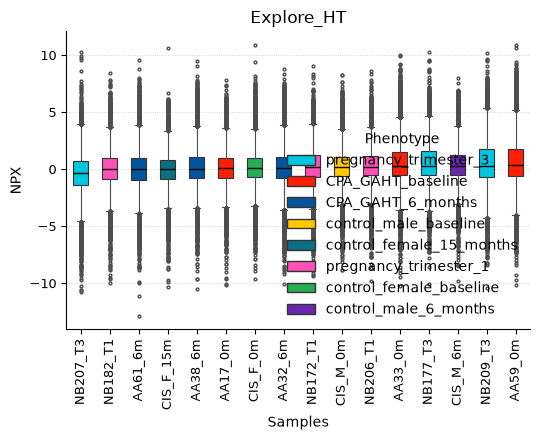

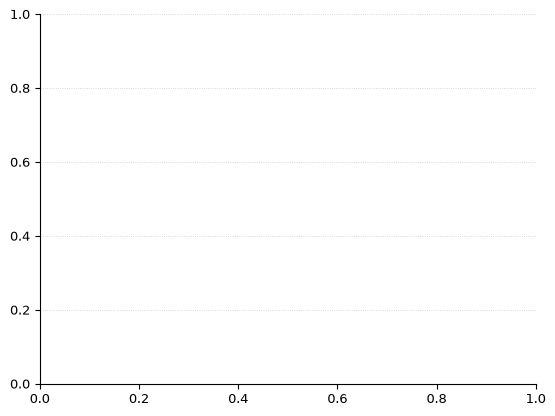

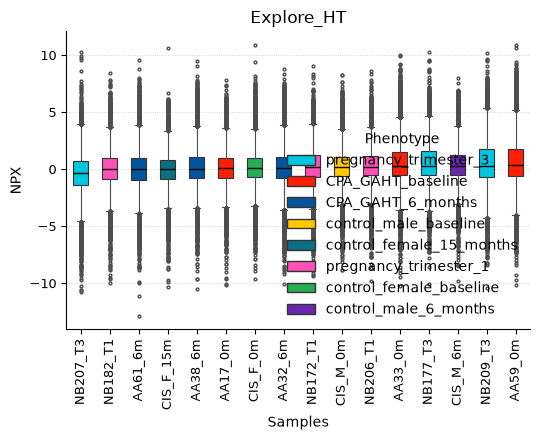

In [62]:
oa.set_plot_theme()

dist_ids = (
    run1.dropna(subset=["Phenotype"])
    .drop_duplicates("SampleID")
    .groupby("Phenotype", observed=True)["SampleID"]
    .head(3)
)
oa.olink_dist_plot(run1.loc[run1["SampleID"].isin(dist_ids)], color_g="Phenotype")


/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/plots/qc.py:85: UserWarning: 
The palette list has fewer values (1) than needed (2) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(


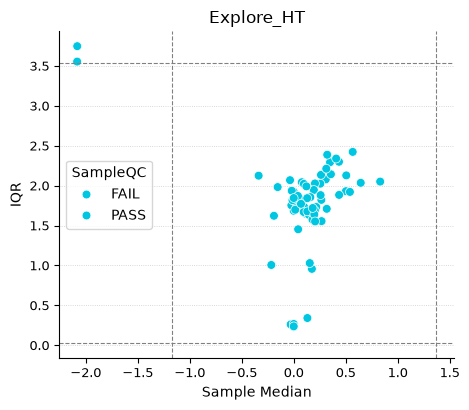

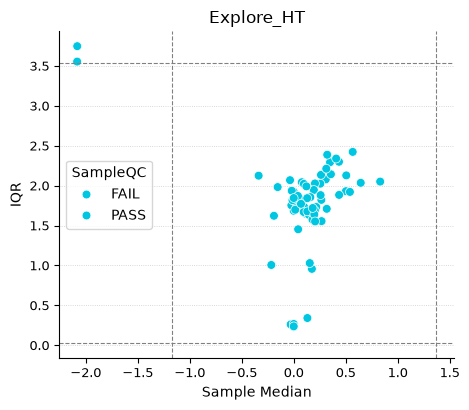

In [63]:
oa.olink_qc_plot(run1_raw, color_g="SampleQC")


## PCA and heatmap

`olink_pca_plot` pivots samples × assays and colors points by a sample-level
column. `olink_heatmap_plot` shows the most variable assays, median-centered.


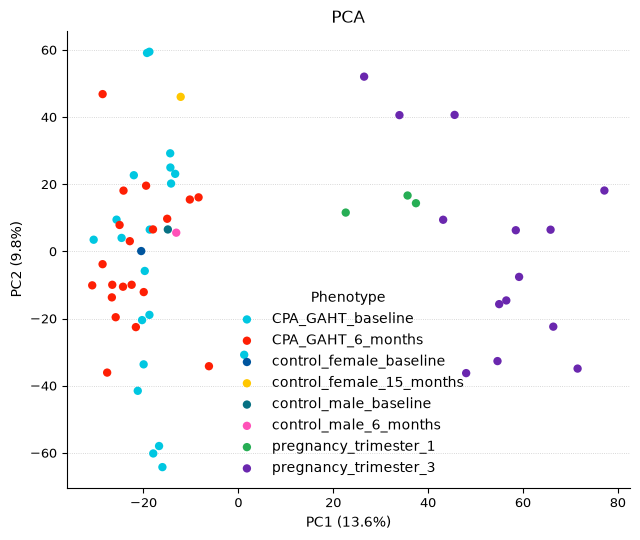

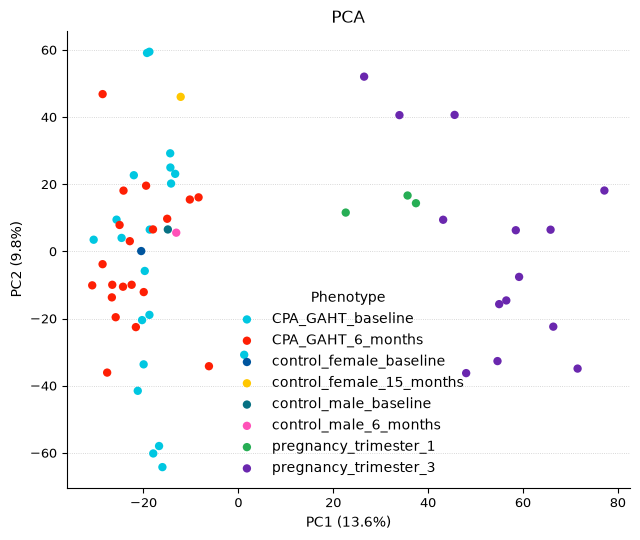

In [64]:
oa.olink_pca_plot(run1, color_g="Phenotype")


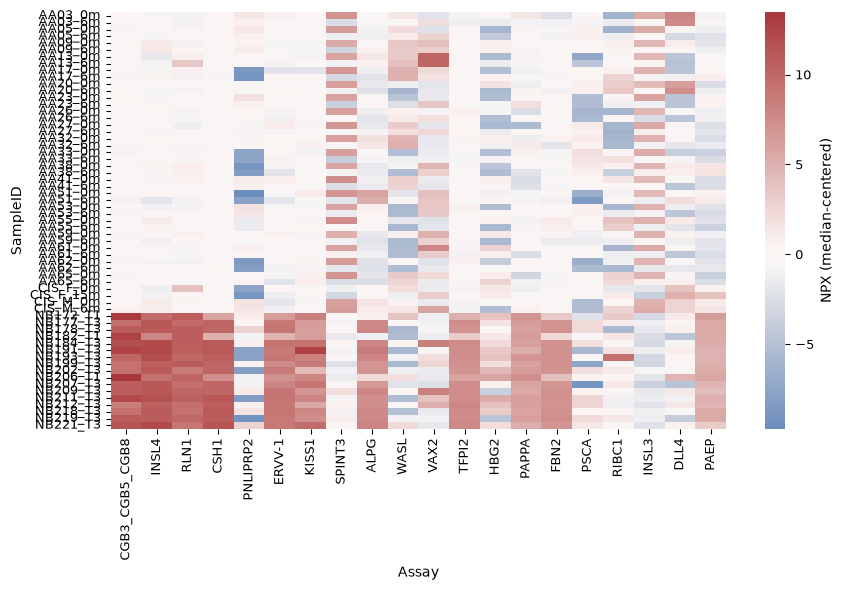

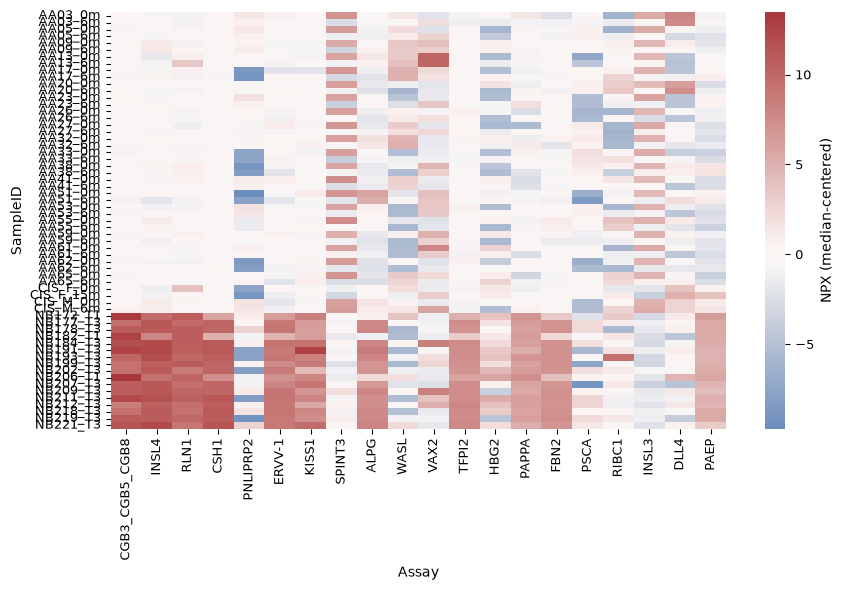

In [65]:
oa.olink_heatmap_plot(run1, n_assays=20)


## Intensity normalization

The two plates share only control well names (`IPC*`, `SC*`, `NC*`), not
study samples. After `clean_npx` those controls are gone, so intensity
(median) normalization is the matching method: it shifts run 2 so per-assay
medians match run 1.


In [66]:
npx = oa.olink_normalization(
    df1=run1,
    df2=run2,
    df1_project_nr="run1",
    df2_project_nr="run2",
    reference_project="run1",
)

print(npx.groupby("Project", observed=True)["SampleID"].nunique())
print()
print(
    npx.dropna(subset=["Phenotype"])
    .drop_duplicates("SampleID")["Phenotype"]
    .value_counts()
    .to_string()
)
npx.head()


/home/thanadol.sutantiwani@Olink.local/Github/OlinkPythonPackage/src/olinkanalyze/qc/check_npx.py:31: UserWarning: More than one column name in df was associated with certain keys. One was selected based on an ordered list. quant: 'NPX' was selected. Options were ['NPX', 'PCNormalizedNPX']. Use preferred_names to select a different column.
  col_names = resolve_column_names(df, preferred_names=preferred_names)


Project
run1    61
run2    42
Name: SampleID, dtype: int64

Phenotype
CPA_GAHT_baseline           21
CPA_GAHT_6_months           21
SPIRO_GAHT_baseline         20
SPIRO_GAHT_6_months         20
pregnancy_trimester_3       14
pregnancy_trimester_1        3
control_male_baseline        1
control_female_15_months     1
control_female_baseline      1
control_male_6_months        1


,SampleID,SampleType,WellID,PlateID,DataAnalysisRefID,OlinkID,...,ExploreVersion,Phenotype,Run,DataFile,Project,Adj_factor
0,NB177_T3,SAMPLE,A1,plate1,D10001,OID40001,...,6.7.2,pregnancy_trimester_3,run 1,X201SC23110522-Z01-F004_NPX.parquet,run1,0.0
1,AA17_0m,SAMPLE,A2,plate1,D10001,OID40001,...,6.7.2,CPA_GAHT_baseline,run 1,X201SC23110522-Z01-F004_NPX.parquet,run1,0.0
2,AA32_6m,SAMPLE,A3,plate1,D10001,OID40001,...,6.7.2,CPA_GAHT_6_months,run 1,X201SC23110522-Z01-F004_NPX.parquet,run1,0.0
3,AA38_6m,SAMPLE,A4,plate1,D10001,OID40001,...,6.7.2,CPA_GAHT_6_months,run 1,X201SC23110522-Z01-F004_NPX.parquet,run1,0.0
4,NB207_T3,SAMPLE,A5,plate1,D10001,OID40001,...,6.7.2,pregnancy_trimester_3,run 1,X201SC23110522-Z01-F004_NPX.parquet,run1,0.0


## `olink_ttest` and volcano

Welch t-tests of CPA GAHT baseline versus 6 months, excluding the run-2
technical replicates (`*_rep`). `olink_volcano_plot` expects the t-test table.


In [67]:
cpa = npx.loc[
    npx["Phenotype"].isin(["CPA_GAHT_baseline", "CPA_GAHT_6_months"])
    & ~npx["SampleID"].astype(str).str.endswith("_rep")
].copy()

print(cpa.drop_duplicates("SampleID")["Phenotype"].value_counts().to_string())

ttest = oa.olink_ttest(cpa, variable="Phenotype")
print("significant (FDR < 0.05):", int((ttest["Threshold"] == "Significant").sum()), "of", len(ttest))
ttest.head(10)


Phenotype
CPA_GAHT_baseline    20
CPA_GAHT_6_months    20
significant (FDR < 0.05): 22 of 5414


,Assay,OlinkID,UniProt,Panel,estimate,CPA_GAHT_6_months,...,conf.low,conf.high,method,alternative,Adjusted_pval,Threshold
0,SPINT3,OID44278,P49223,Explore_HT,-7.907653,-6.161389,...,-8.574948,-7.240358,Welch Two Sample t-test,two-sided,1.761963e-16,Significant
1,INSL3,OID43864,P51460,Explore_HT,-5.344663,-3.884943,...,-5.815383,-4.873943,Welch Two Sample t-test,two-sided,4.479514e-16,Significant
2,EDDM3B,OID43651,P56851,Explore_HT,-2.665579,-1.993433,...,-2.970653,-2.360504,Welch Two Sample t-test,two-sided,1.945660e-14,Significant
3,PRL,OID44871,P01236,Explore_HT,1.382163,1.832290,...,1.083806,1.680520,Welch Two Sample t-test,two-sided,3.347859e-08,Significant
4,PROK1,OID44127,P58294,Explore_HT,-1.287513,-1.035559,...,-1.635653,-0.939373,Welch Two Sample t-test,two-sided,5.902744e-06,Significant
5,TEX101,OID44316,Q9BY14,Explore_HT,-2.077347,-0.910150,...,-2.664195,-1.490498,Welch Two Sample t-test,two-sided,5.179212e-05,Significant
6,CXCL13,OID44586,O43927,Explore_HT,1.841983,1.187568,...,1.290075,2.393890,Welch Two Sample t-test,two-sided,3.242851e-04,Significant
7,ACRV1,OID43322,P26436,Explore_HT,-1.372004,-0.428330,...,-1.795591,-0.948417,Welch Two Sample t-test,two-sided,5.065450e-04,Significant
8,NCAM1,OID45387,P13591,Explore_HT,-0.553380,0.117024,...,-0.741970,-0.364790,Welch Two Sample t-test,two-sided,8.687154e-04,Significant
9,IGFBP7,OID45154,Q16270,Explore_HT,-0.406833,0.155283,...,-0.571158,-0.242507,Welch Two Sample t-test,two-sided,7.872747e-03,Significant


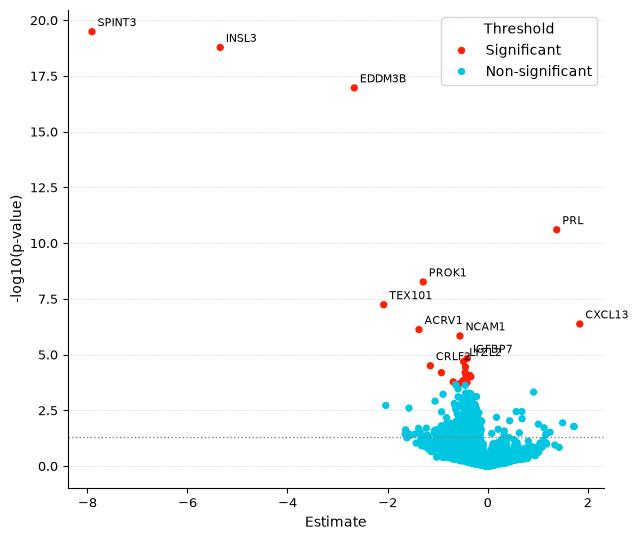

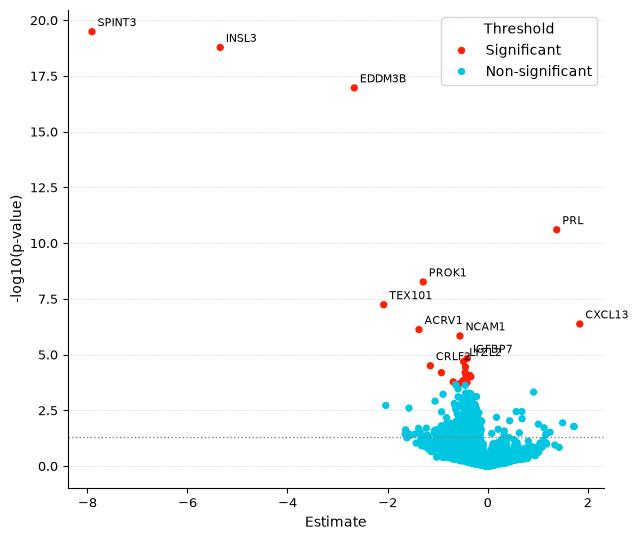

In [68]:
oa.olink_volcano_plot(ttest, olinkid_list=ttest["OlinkID"].head(12))


## Wilcoxon and paired t-test

`olink_wilcox` is the rank-sum analogue of the two-group t-test. Sample IDs
encode subject and time (`AA17_0m` / `AA17_6m`), so a paired t-test uses
`pair_id="Subject"`.


In [69]:
wilcox = oa.olink_wilcox(cpa, variable="Phenotype")
print("Wilcoxon significant:", int((wilcox["Threshold"] == "Significant").sum()), "of", len(wilcox))

cpa["Subject"] = cpa["SampleID"].astype(str).str.rsplit("_", n=1).str[0]
paired = oa.olink_ttest(cpa, variable="Phenotype", pair_id="Subject")
print("paired t-test significant:", int((paired["Threshold"] == "Significant").sum()), "of", len(paired))

compare = (
    ttest.set_index("OlinkID")[["Assay", "estimate", "Adjusted_pval"]]
    .join(wilcox.set_index("OlinkID")["Adjusted_pval"].rename("wilcox_FDR"))
    .join(paired.set_index("OlinkID")["Adjusted_pval"].rename("paired_FDR"))
    .sort_values("Adjusted_pval")
)
compare.head(8)


Wilcoxon significant: 16 of 5414
paired t-test significant: 265 of 5414


,Assay,estimate,Adjusted_pval,wilcox_FDR,paired_FDR
OlinkID,,,,,
OID44278,SPINT3,-7.907653,1.761963e-16,0.000123,3.524398e-12
OID43864,INSL3,-5.344663,4.479514e-16,0.000123,3.524398e-12
OID43651,EDDM3B,-2.665579,1.945660e-14,0.000123,8.409570e-12
OID44871,PRL,1.382163,3.347859e-08,0.000155,1.806986e-07
OID44127,PROK1,-1.287513,5.902744e-06,0.000535,4.920623e-08
OID44316,TEX101,-2.077347,5.179212e-05,0.000813,5.271766e-06
OID44586,CXCL13,1.841983,3.242851e-04,0.000173,9.985044e-05
OID43322,ACRV1,-1.372004,5.065450e-04,0.000124,3.333455e-04


## ANOVA

One-way ANOVA across the five largest phenotype groups, then pairwise Welch
post-hoc tests.


In [70]:
anova_groups = [
    "CPA_GAHT_baseline",
    "CPA_GAHT_6_months",
    "SPIRO_GAHT_baseline",
    "SPIRO_GAHT_6_months",
    "pregnancy_trimester_3",
]
anova_df = npx.loc[
    npx["Phenotype"].isin(anova_groups)
    & ~npx["SampleID"].astype(str).str.endswith("_rep")
].copy()

print(anova_df.drop_duplicates("SampleID")["Phenotype"].value_counts().to_string())

anova = oa.olink_anova(anova_df, variable="Phenotype")
print("ANOVA significant:", int((anova["Threshold"] == "Significant").sum()), "of", len(anova))
anova.head()


Phenotype
CPA_GAHT_baseline        20
CPA_GAHT_6_months        20
SPIRO_GAHT_baseline      20
SPIRO_GAHT_6_months      20
pregnancy_trimester_3    14
ANOVA significant: 1473 of 5414


,Assay,OlinkID,UniProt,Panel,statistic,p.value,method,variable,Adjusted_pval,Threshold
0,CSH1,OID45344,P0DML2,Explore_HT,4443.046711,1.562198e-101,One-way ANOVA,Phenotype,8.457740e-98,Significant
1,CGB3_CGB5_CGB8,OID45334,P0DN86,Explore_HT,1080.857823,1.618247e-74,One-way ANOVA,Phenotype,4.380594e-71,Significant
2,TFPI2,OID44974,P48307,Explore_HT,843.502124,7.746896e-70,One-way ANOVA,Phenotype,1.398056e-66,Significant
3,FLT1,OID43721,P17948,Explore_HT,790.751787,1.268652e-68,One-way ANOVA,Phenotype,1.717120e-65,Significant
4,INSL4,OID43865,Q14641,Explore_HT,769.180999,4.194764e-68,One-way ANOVA,Phenotype,4.542091e-65,Significant


In [71]:
posthoc = oa.olink_anova_posthoc(anova_df, variable="Phenotype")
print(posthoc["contrast"].value_counts().to_string())
posthoc.sort_values("Adjusted_pval").head(8)


contrast
SPIRO_GAHT_6_months - SPIRO_GAHT_baseline      5419
CPA_GAHT_6_months - pregnancy_trimester_3      5414
CPA_GAHT_baseline - pregnancy_trimester_3      5414
SPIRO_GAHT_baseline - pregnancy_trimester_3    5414
SPIRO_GAHT_6_months - pregnancy_trimester_3    5414
CPA_GAHT_6_months - CPA_GAHT_baseline          5414
CPA_GAHT_baseline - SPIRO_GAHT_baseline        5414
CPA_GAHT_baseline - SPIRO_GAHT_6_months        5414
CPA_GAHT_6_months - SPIRO_GAHT_baseline        5414
CPA_GAHT_6_months - SPIRO_GAHT_6_months        5414


,Assay,OlinkID,UniProt,Panel,estimate,CPA_GAHT_6_months,...,contrast,SPIRO_GAHT_6_months,SPIRO_GAHT_baseline,pregnancy_trimester_3,Adjusted_pval,Threshold
0,TFPI2,OID44974,P48307,Explore_HT,-7.702134,-0.087223,...,CPA_GAHT_6_months - pregnancy_trimester_3,NaN,NaN,7.614911,2.067493e-31,Significant
1,TFPI2,OID44974,P48307,Explore_HT,-7.458132,NaN,...,CPA_GAHT_baseline - pregnancy_trimester_3,NaN,NaN,7.614911,4.409567e-30,Significant
2,INSL4,OID43865,Q14641,Explore_HT,-11.503416,NaN,...,CPA_GAHT_baseline - pregnancy_trimester_3,NaN,NaN,9.715290,1.450562e-28,Significant
3,INSL4,OID43865,Q14641,Explore_HT,-11.473813,-1.758524,...,CPA_GAHT_6_months - pregnancy_trimester_3,NaN,NaN,9.715290,1.450562e-28,Significant
4,FLT1,OID43721,P17948,Explore_HT,-4.175130,-0.393844,...,CPA_GAHT_6_months - pregnancy_trimester_3,NaN,NaN,3.781286,3.026688e-28,Significant
5,INSL4,OID43865,Q14641,Explore_HT,-11.544408,NaN,...,SPIRO_GAHT_baseline - pregnancy_trimester_3,NaN,-1.829119,9.715290,3.457540e-28,Significant
6,FLT1,OID43721,P17948,Explore_HT,-3.900732,NaN,...,SPIRO_GAHT_6_months - pregnancy_trimester_3,-0.119446,NaN,3.781286,4.467108e-28,Significant
7,TFPI2,OID44974,P48307,Explore_HT,-7.529948,NaN,...,SPIRO_GAHT_6_months - pregnancy_trimester_3,0.084962,NaN,7.614911,6.882026e-28,Significant


## LOD

`olink_lod` flags NPX below the assay LOD. These Explore HT parquet files do
not include an LOD column, so the call is expected to fail. Use a Standard
NPX export (or the optional `Olink_CPA_SPIRO_GAHT_and_pregnancy.npx.csv` from
the same PRIDE dataset) if you need BelowLOD flags.


In [72]:
log = oa.extract_check_log(run1)
print("LOD in check_log:", "lod" in log["col_names"])
try:
    oa.olink_lod(run1)
except ValueError as exc:
    print(exc)


LOD in check_log: False
LOD column is required for olink_lod().
